# Lab 6 · ECG heartbeat classification
This notebook classifies one extracted MIT-BIH heartbeat into N (normal or non-ectopic), S (supraventricular ectopic), V (ventricular ectopic), F (fusion), or Q (paced or unclassifiable). The two headerless CSVs in `data/` are from the [Kaggle ECG Heartbeat Categorization Dataset](https://www.kaggle.com/datasets/shayanfazeli/heartbeat).

Requires Python 3 with NumPy, pandas, matplotlib, scikit-learn, PyTorch and IPython. Run from the notebook directory.

## Part A · Load and inspect the data

In [1]:
from pathlib import Path
from time import perf_counter
from copy import deepcopy
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)

CLASSES = list("NSVFQ")
LABELS = np.arange(len(CLASSES))
SAMPLES = 187
TIME_MS = np.arange(SAMPLES) * 8
DATA = Path("data")

train_df = pd.read_csv(DATA / "mitbih_train.csv", header=None, dtype=np.float32)
test_df = pd.read_csv(DATA / "mitbih_test.csv", header=None, dtype=np.float32)
for split, frame in [("Train", train_df), ("Test", test_df)]:
    print(f"{split} shape: {frame.shape}, missing values: {frame.isna().sum().sum()}")
    assert frame.shape[1] == SAMPLES + 1 and not frame.isna().any().any()
    assert frame[SAMPLES].isin(LABELS).all()

def distribution(labels):
    counts = pd.Series(labels).value_counts().reindex(LABELS, fill_value=0)
    return pd.DataFrame({"Count": counts.to_numpy(),
                         "Percent": (100 * counts / counts.sum()).to_numpy()}, index=CLASSES)

counts = pd.concat({"Train": distribution(train_df[SAMPLES]),
                    "Test": distribution(test_df[SAMPLES])}, axis=1)
display(counts.round(2))
X = train_df.iloc[:, :SAMPLES].to_numpy(copy=True)
y = train_df[SAMPLES].to_numpy(dtype=np.int64)
del train_df

Train shape: (87554, 188), missing values: 0
Test shape: (21892, 188), missing values: 0


Train           Test        
   Count Percent  Count Percent
N  72471   82.77  18118   82.76
S   2223    2.54    556    2.54
V   5788    6.61   1448    6.61
F    641    0.73    162    0.74
Q   6431    7.35   1608    7.35

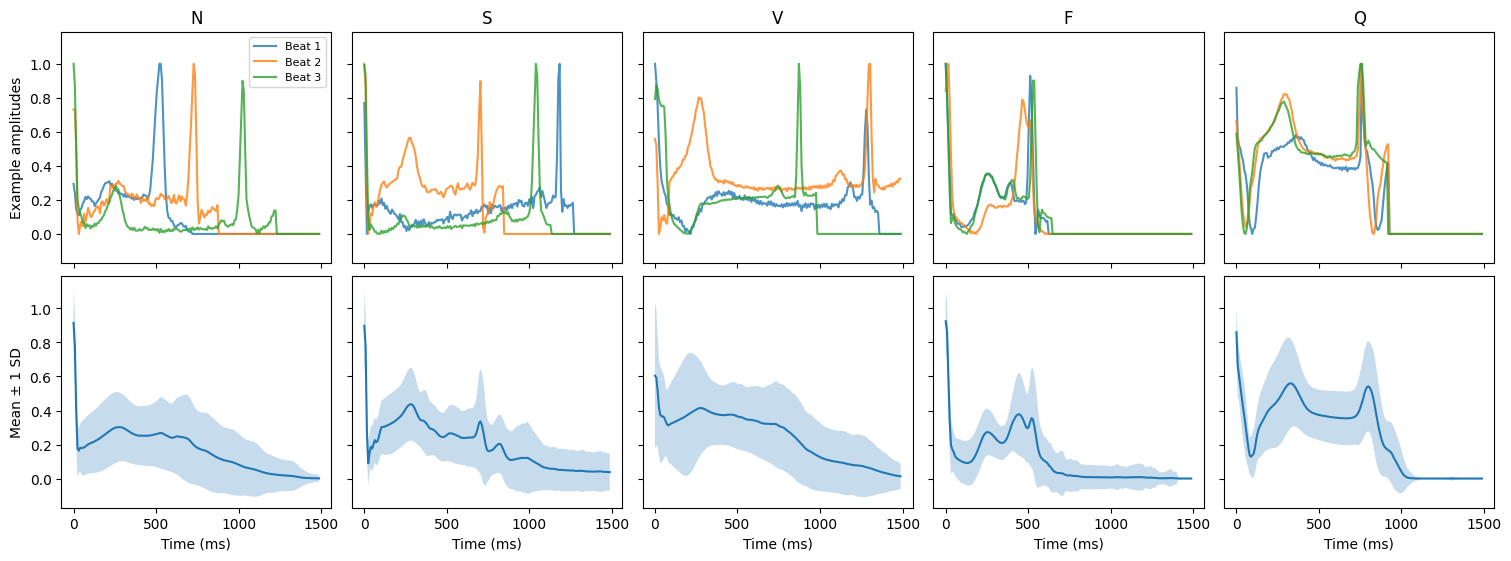

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5.5), sharex=True, sharey=True,
                         layout="constrained")
rng = np.random.default_rng(SEED)
for label, name in enumerate(CLASSES):
    beats = X[y == label]
    for number, beat in enumerate(beats[rng.choice(len(beats), 3, replace=False)], 1):
        axes[0, label].plot(TIME_MS, beat, alpha=0.8, label=f"Beat {number}")
    mean, std = beats.mean(axis=0), beats.std(axis=0)
    axes[1, label].plot(TIME_MS, mean)
    axes[1, label].fill_between(TIME_MS, mean - std, mean + std, alpha=0.25)
    axes[0, label].set_title(name)
    axes[1, label].set_xlabel("Time (ms)")
axes[0, 0].set_ylabel("Example amplitudes")
axes[1, 0].set_ylabel("Mean ± 1 SD")
axes[0, 0].legend(fontsize=8)
plt.show()

Each row contains 187 ordered samples of one beat at 125 Hz and its class label in column 187. Samples are scaled and shorter beats are zero-padded. The 109,446 rows are repeated observations from recordings originating from 47 people.

An always-N classifier gets accuracy equal to the N fraction of each file (82.77% on train and 82.76% on test) and F sensitivity of 0%, since it catches zero true F beats.

In the training plots, V and Q often stand out because their peak shapes and post-peak waveforms differ from the common N profile. N and S are harder to separate visually because their early peaks overlap. F has variable morphology, and individual F beats can resemble N or V. These impressions depend on which traces are sampled.

## Part B · Stratified split and baselines
The supplied test file is used above for the required descriptive checks. Model fitting, checkpoint selection and comparisons use only the supplied training file. Choosing based on test scores would favor models that happen to score well on those test beats and bias the final estimate.

In [3]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print(f"Fit beats: {len(y_fit):,} | Validation beats: {len(y_val):,}")
display(pd.concat({"Fit": distribution(y_fit), "Validation": distribution(y_val)}, axis=1).round(2))

models = {}
validation_predictions = {}
fit_seconds = {}

def fit_classifier(name, estimator, fit_inputs, validation_inputs, transform=None):
    start = perf_counter()
    with threadpool_limits(limits=4):
        estimator.fit(fit_inputs, y_fit)
    fit_seconds[name] = perf_counter() - start
    validation_predictions[name] = estimator.predict(validation_inputs)
    models[name] = estimator.predict if transform is None else lambda beats: estimator.predict(transform(beats))

fit_classifier("Majority baseline", DummyClassifier(strategy="most_frequent", random_state=SEED),
               X_fit, X_val)
for name, weights in [("Logistic", None), ("Balanced logistic", "balanced")]:
    logistic = make_pipeline(StandardScaler(), LogisticRegression(
        solver="lbfgs", max_iter=600, random_state=SEED, class_weight=weights
    ))
    fit_classifier(name, logistic, X_fit, X_val)

Fit beats: 70,043 | Validation beats: 17,511


Fit         Validation        
   Count Percent      Count Percent
N  57977   82.77      14494   82.77
S   1778    2.54        445    2.54
V   4630    6.61       1158    6.61
F    513    0.73        128    0.73
Q   5145    7.35       1286    7.34

In [4]:
plain = confusion_matrix(y_val, validation_predictions["Logistic"], labels=LABELS)
balanced = confusion_matrix(y_val, validation_predictions["Balanced logistic"], labels=LABELS)
display(pd.DataFrame(balanced - plain, index=pd.Index(CLASSES, name="True"),
                     columns=pd.Index(CLASSES, name="Predicted")))
normal_cost = plain[0, 0] - balanced[0, 0]
changes = ", ".join(f"{CLASSES[i]} {balanced[i, i] - plain[i, i]:+d}" for i in LABELS[1:])
display(Markdown(f"Balancing changed the number of correctly recognized minority beats by "
                 f"**{changes}**. It cost **{normal_cost:,}** correct N predictions on validation. "
                 "The matrix above gives the change in every true/predicted cell."))

Predicted,N,S,V,F,Q
True,,,,,
N,-4891,1636,1754,1123,378
S,-132,107,3,18,4
V,-596,36,468,82,10
F,-76,1,1,74,0
Q,-93,5,28,3,57


Balancing changed the number of correctly recognized minority beats by **S +107, V +468, F +74, Q +57**. It cost **4,891** correct N predictions on validation. The matrix above gives the change in every true/predicted cell.

Balanced logistic regression gives rarer classes greater weight in the training loss. The change in diagonal counts shows which classes gained sensitivity. In this run it recovered 107 more S, 468 more V, 74 more F, and 57 more Q beats. It made 4,891 fewer correct N predictions, with a net increase of 1,754 N-to-V errors. F sensitivity rose from 28.1% to 85.9%, while F precision fell from 69.2% to 8.1%.

## Part C · Raw signals, engineered features and a 1D CNN
Use the same Extra Trees settings for both representations. The CNN trains on the raw signals, uses square-root inverse-frequency loss weights computed on the fit set, and restores the checkpoint with the highest validation macro F1. It stops after six epochs without improvement, with a 35-epoch cap.

In [5]:
def non_padded_length(beats):
    last = np.argmax((beats != 0)[:, ::-1], axis=1)
    return np.where(np.any(beats != 0, axis=1), beats.shape[1] - last, 0)

def beat_features(beats):
    return np.column_stack([
        beats.max(axis=1),
        beats.argmax(axis=1),
        beats.min(axis=1),
        beats.std(axis=1),
        np.sum(beats ** 2, axis=1),
        non_padded_length(beats),
        np.sum((beats[:, 1:] + beats[:, :-1]) * 0.004, axis=1),
    ])

trees = partial(ExtraTreesClassifier, n_estimators=100, random_state=SEED, n_jobs=4)
fit_classifier("Raw Extra Trees", trees(), X_fit, X_val)
fit_classifier("Feature Extra Trees", trees(), beat_features(X_fit), beat_features(X_val),
               transform=beat_features)

C:\Users\anshu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Trained for 16 epochs | Best epoch: 10 | Macro F1: 0.9119


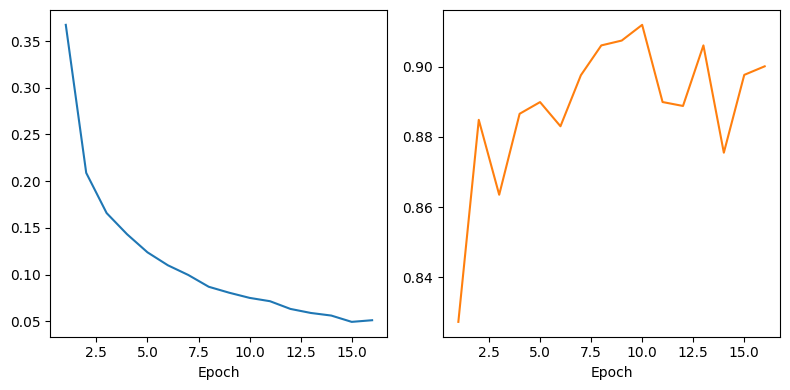

In [6]:
def signal_tensor(beats):
    return torch.from_numpy(np.ascontiguousarray(beats[:, None, :]))

fit_loader = DataLoader(
    TensorDataset(signal_tensor(X_fit), torch.from_numpy(y_fit)), batch_size=256,
    shuffle=True, generator=torch.Generator().manual_seed(SEED)
)

cnn = nn.Sequential(
    nn.Conv1d(1, 16, 7, padding=3), nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(16, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
    nn.Flatten(), nn.Linear(64 * 23, 64), nn.ReLU(), nn.Dropout(0.15),
    nn.Linear(64, len(CLASSES)),
)

@torch.inference_mode()
def predict_cnn(beats):
    cnn.eval()
    return torch.cat([cnn(batch).argmax(dim=1)
                      for batch in signal_tensor(beats).split(512)]).numpy()

weights = np.sqrt(len(y_fit) / (len(CLASSES) * np.bincount(y_fit)))
loss_function = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32))
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.001)
history = []
best_score = -np.inf
start = perf_counter()
for epoch in range(1, 36):
    cnn.train()
    total_loss = 0.0
    for beat_batch, label_batch in fit_loader:
        optimizer.zero_grad()
        loss = loss_function(cnn(beat_batch), label_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(label_batch)

    predictions = predict_cnn(X_val)
    score = f1_score(y_val, predictions, labels=LABELS, average="macro", zero_division=0)
    history.append({"Epoch": epoch, "Fit loss": total_loss / len(y_fit),
                    "Validation macro F1": score})
    if score > best_score:
        best_score, best_epoch = score, epoch
        best_weights = deepcopy(cnn.state_dict())
        best_predictions = predictions
    if epoch - best_epoch >= 6:
        break

cnn.load_state_dict(best_weights)
fit_seconds["1D CNN"] = perf_counter() - start
validation_predictions["1D CNN"] = best_predictions
models["1D CNN"] = predict_cnn
print(f"Trained for {epoch} epochs | Best epoch: {best_epoch} | Macro F1: {best_score:.4f}")
pd.DataFrame(history).set_index("Epoch").plot(subplots=True, figsize=(8, 4),
                                             layout=(1, 2), legend=False)
plt.tight_layout()
plt.show()

In [7]:
raw_score, feature_score = [
    f1_score(y_val, validation_predictions[name], labels=LABELS, average="macro", zero_division=0)
    for name in ["Raw Extra Trees", "Feature Extra Trees"]
]
outcome = ("Raw values worked better" if raw_score > feature_score else
           "Engineered features worked better" if feature_score > raw_score else "Both tied")
reason = ("The raw values retain the positions and shapes of local waves that the summaries discard."
          if raw_score >= feature_score else
          "The summaries may reduce the impact of small sample-by-sample shifts and noise.")
display(Markdown(f"**{outcome}** by validation macro F1 "
                 f"(raw {raw_score:.4f}, engineered {feature_score:.4f}). {reason}"))

**Raw values worked better** by validation macro F1 (raw 0.8852, engineered 0.6427). The raw values retain the positions and shapes of local waves that the summaries discard.

Raw Extra Trees scored 0.8852 validation macro F1 versus 0.6427 for the engineered features. Raw samples preserved waveform details that the seven summaries compressed. In the run saved here, the 1D CNN led all six models with macro F1 of 0.9119.

Convolutions can learn local peak widths, slopes, and sequences of neighboring deflections. Pooling tolerates small shifts, while the dense layer can combine evidence from different time regions. The seven summaries discard most of this ordering.

The last nonzero position can reflect both the segment duration and the segmentation or padding convention. Compare a length-only model, the full model, and a model retrained on fixed-length windows aligned to the peak with the original padded tails excluded. Check performance on the same validation beats and look at per-class changes. A substantial decline after removing access to length would indicate reliance on that cue, although truncation could also remove genuine morphology.

## Part D · Validation evaluation and model selection
The diagonal of each row-normalized matrix is class sensitivity. Precision answers how many predictions of a class were correct. Undefined precision is reported as zero when a model never predicts that class.

,Split,Model,Accuracy,Macro F1,Fit seconds,Sens N,Sens S,Sens V,Sens F,Sens Q,PPV N,PPV S,PPV V,PPV F,PPV Q
0,Validation,1D CNN,0.9834,0.9119,257.3779,0.9923,0.8247,0.9508,0.7734,0.9891,0.9903,0.8417,0.9633,0.8049,0.9891
1,Validation,Raw Extra Trees,0.9777,0.8852,12.6734,0.9985,0.6427,0.8964,0.6328,0.9666,0.9768,0.9728,0.9756,0.9205,0.9944
2,Validation,Logistic,0.9135,0.6569,24.2192,0.9816,0.4494,0.3351,0.2812,0.8904,0.9252,0.8230,0.6299,0.6923,0.9370
3,Validation,Feature Extra Trees,0.9027,0.6427,2.2510,0.9721,0.3596,0.6028,0.2969,0.6400,0.9204,0.6557,0.8060,0.6333,0.7959
4,Validation,Balanced logistic,0.6745,0.4820,33.7219,0.6441,0.6899,0.7392,0.8594,0.9347,0.9735,0.1514,0.2983,0.0814,0.7193
5,Validation,Majority baseline,0.8277,0.1811,0.1517,1.0000,0.0000,0.0000,0.0000,0.0000,0.8277,0.0000,0.0000,0.0000,0.0000


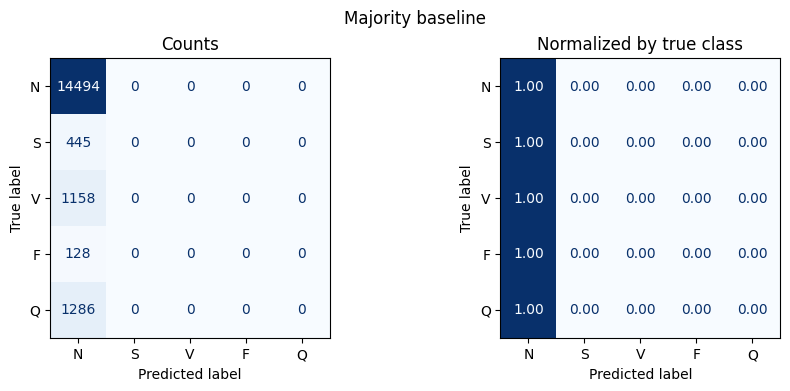

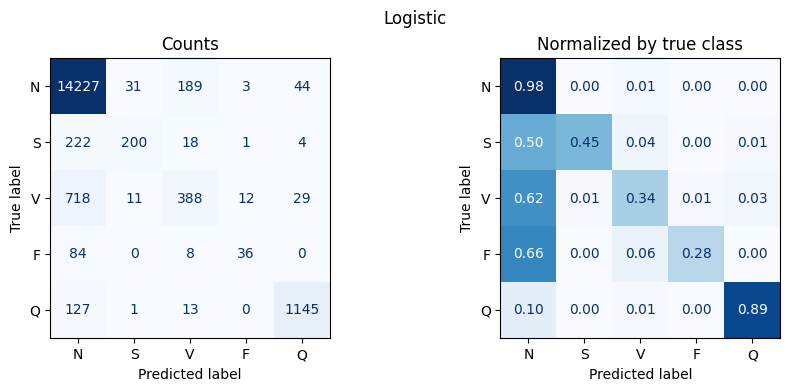

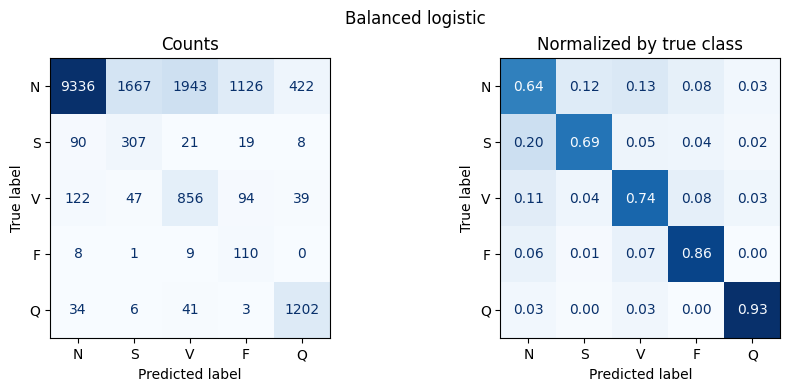

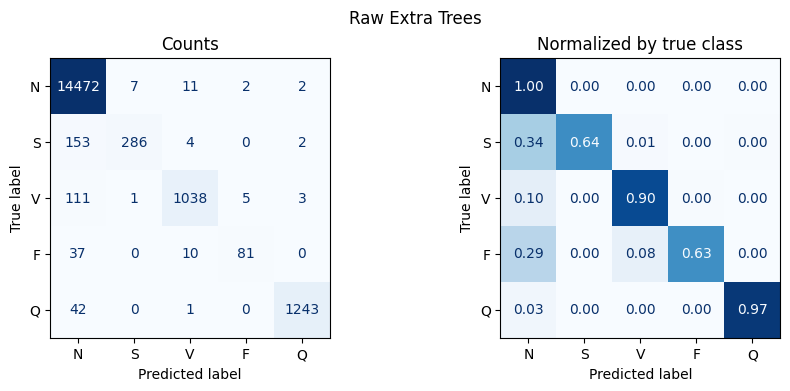

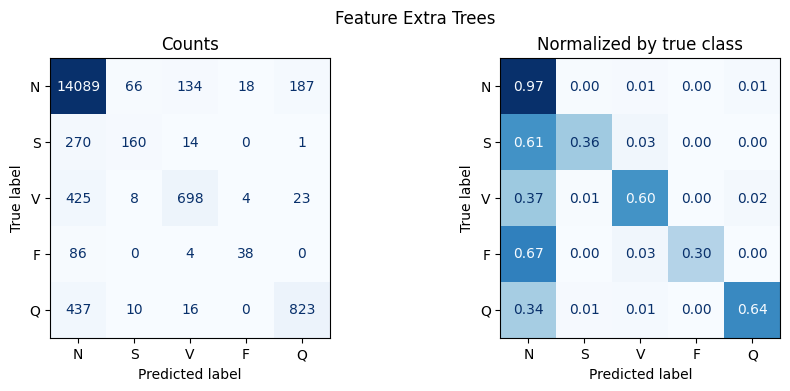

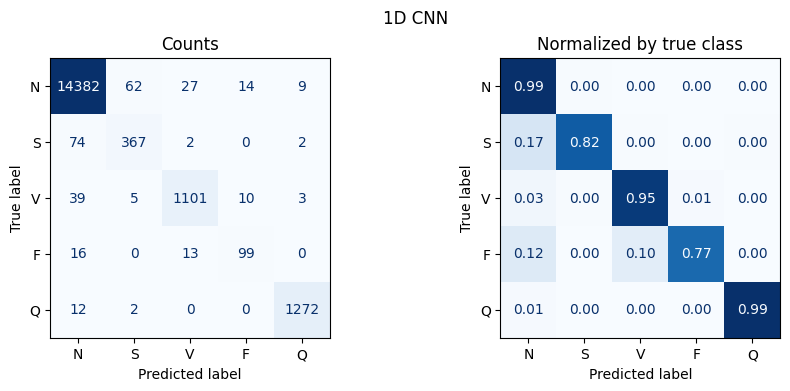

**Selected 1D CNN** because it had the highest validation macro F1 (0.9119), with accuracy 0.9834.

In [8]:
def metrics(name, split, truth, predictions):
    precision, sensitivity, _, _ = precision_recall_fscore_support(
        truth, predictions, labels=LABELS, zero_division=0
    )
    return {
        "Split": split, "Model": name,
        "Accuracy": accuracy_score(truth, predictions),
        "Macro F1": f1_score(truth, predictions, labels=LABELS, average="macro", zero_division=0),
        "Fit seconds": fit_seconds[name],
        **{f"Sens {name}": value for name, value in zip(CLASSES, sensitivity)},
        **{f"PPV {name}": value for name, value in zip(CLASSES, precision)},
    }

def plot_matrices(name, truth, predictions):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
    for ax, normalize, title, fmt in [
        (axes[0], None, "Counts", "d"),
        (axes[1], "true", "Normalized by true class", ".2f"),
    ]:
        matrix = confusion_matrix(truth, predictions, labels=LABELS, normalize=normalize)
        ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format=fmt
        )
        ax.set_title(title)
    fig.suptitle(name)
    plt.show()

validation_table = pd.DataFrame([
    metrics(name, "Validation", y_val, predictions)
    for name, predictions in validation_predictions.items()
]).sort_values("Macro F1", ascending=False, kind="stable").reset_index(drop=True)
display(validation_table.round(4))
for name, predictions in validation_predictions.items():
    plot_matrices(name, y_val, predictions)

winner = validation_table.iloc[0]
selected = winner["Model"]
selected_val_predictions = validation_predictions[selected]
display(Markdown(f"**Selected {selected}** because it had the highest validation macro F1 "
                 f"({winner['Macro F1']:.4f}), with accuracy {winner['Accuracy']:.4f}."))

Most confused pair: N and S (136 errors in both directions).
Largest directional error: S to N (74 beats).


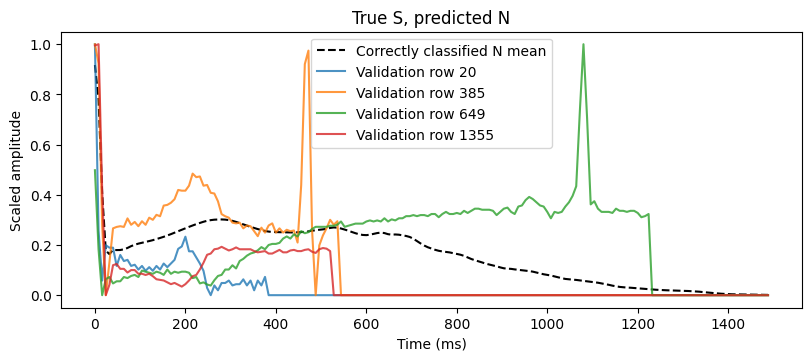

Mean absolute distance over first 25 samples: 0.149 to true-class mean, 0.130 to predicted-class mean.
Mean absolute distance over full beat: 0.142 to true-class mean, 0.121 to predicted-class mean.


In [9]:
def plot_examples(beats, indices, title, subtitle):
    fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
    for index in indices[:4]:
        ax.plot(TIME_MS, beats[index], alpha=0.8, label=subtitle(index))
    ax.set(title=title, xlabel="Time (ms)", ylabel="Scaled amplitude")
    if len(indices):
        ax.legend()
    plt.show()

errors = confusion_matrix(y_val, selected_val_predictions, labels=LABELS)
np.fill_diagonal(errors, 0)
pair_counts = np.triu(errors + errors.T, k=1)
first, second = np.unravel_index(pair_counts.argmax(), pair_counts.shape)
true_label, predicted_label = np.unravel_index(errors.argmax(), errors.shape)
wrong = np.flatnonzero((y_val == true_label) & (selected_val_predictions == predicted_label))
print(f"Most confused pair: {CLASSES[first]} and {CLASSES[second]} "
      f"({pair_counts[first, second]} errors in both directions).")
print(f"Largest directional error: {CLASSES[true_label]} to {CLASSES[predicted_label]} "
      f"({len(wrong)} beats).")
representatives = np.flatnonzero((y_val == predicted_label) &
                                (selected_val_predictions == predicted_label))
reference = X_val[representatives].mean(axis=0)
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(TIME_MS, reference, color="black", linestyle="--",
        label=f"Correctly classified {CLASSES[predicted_label]} mean")
for index in wrong[:4]:
    ax.plot(TIME_MS, X_val[index], alpha=0.8, label=f"Validation row {index}")
ax.set(title=f"True {CLASSES[true_label]}, predicted {CLASSES[predicted_label]}",
       xlabel="Time (ms)", ylabel="Scaled amplitude")
ax.legend()
plt.show()

examples = X_val[wrong[:4]]
true_mean = X_val[y_val == true_label].mean(axis=0)
for region, section in [("first 25 samples", slice(0, 25)), ("full beat", slice(None))]:
    distance = np.abs(examples[:, section] - true_mean[section]).mean()
    reference_distance = np.abs(examples[:, section] - reference[section]).mean()
    print(f"Mean absolute distance over {region}: "
          f"{distance:.3f} to true-class mean, {reference_distance:.3f} to predicted-class mean.")

Macro F1 gives each class equal influence, so a model cannot look strong just by labeling most beats N. It can still hide poor sensitivity for a particular class, different costs for different errors, and performance variation by patient.

N and S were the most confused pair in the saved run, with 136 errors across both directions, including 74 S beats predicted as N. The four plotted S-to-N errors were closer to the N reference than the S average both over the first 25 samples (mean absolute distance 0.130 versus 0.149) and over the full beat (0.121 versus 0.142). Similar early deflections and overall shape may help explain the confusion. These distances describe resemblance and cannot establish what the CNN used.

I would prioritize reducing missed V beats when the tool is used to queue beats for review. A lower threshold on the V score can flag more candidate V beats and may increase false V alarms from N. Choose that threshold on validation, tracking V recall, V precision, and the number of N-to-V errors against reviewer capacity.

## Part E · One final test evaluation
The selected model generates one set of test predictions. All test reporting below reuses those predictions.

,Split,Model,Accuracy,Macro F1,Fit seconds,Sens N,Sens S,Sens V,Sens F,Sens Q,PPV N,PPV S,PPV V,PPV F,PPV Q
0,Validation,1D CNN,0.9834,0.9119,257.3779,0.9923,0.8247,0.9508,0.7734,0.9891,0.9903,0.8417,0.9633,0.8049,0.9891
1,Validation,Raw Extra Trees,0.9777,0.8852,12.6734,0.9985,0.6427,0.8964,0.6328,0.9666,0.9768,0.9728,0.9756,0.9205,0.9944
2,Validation,Logistic,0.9135,0.6569,24.2192,0.9816,0.4494,0.3351,0.2812,0.8904,0.9252,0.8230,0.6299,0.6923,0.9370
3,Validation,Feature Extra Trees,0.9027,0.6427,2.2510,0.9721,0.3596,0.6028,0.2969,0.6400,0.9204,0.6557,0.8060,0.6333,0.7959
4,Validation,Balanced logistic,0.6745,0.4820,33.7219,0.6441,0.6899,0.7392,0.8594,0.9347,0.9735,0.1514,0.2983,0.0814,0.7193
5,Validation,Majority baseline,0.8277,0.1811,0.1517,1.0000,0.0000,0.0000,0.0000,0.0000,0.8277,0.0000,0.0000,0.0000,0.0000
6,Test,1D CNN,0.9828,0.9070,257.3779,0.9933,0.7950,0.9427,0.7963,0.9845,0.9892,0.8516,0.9660,0.7633,0.9912


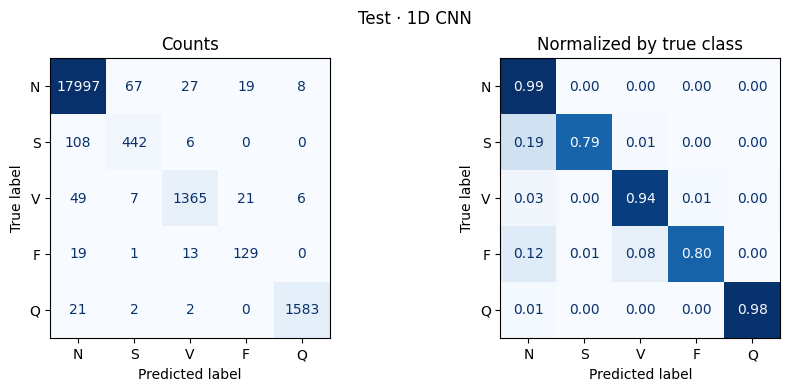

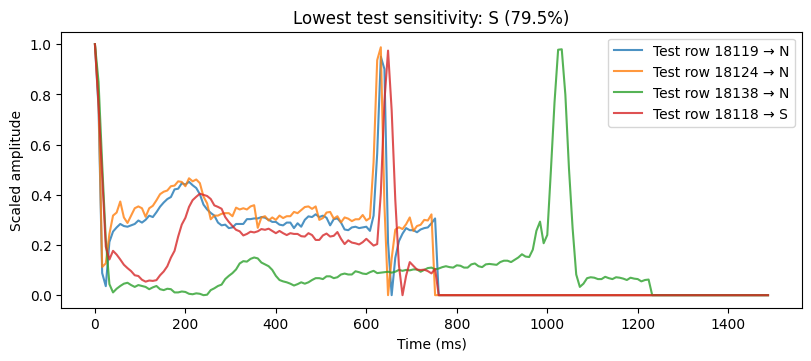

Test macro F1 was **0.9070** versus **0.9119** on validation (-0.49 points). Accuracy changed by **-0.06 points**. The lowest test sensitivity was **S (79.5%)** versus **82.5%** on validation.

In [10]:
X_test = test_df.iloc[:, :SAMPLES].to_numpy(copy=True)
y_test = test_df[SAMPLES].to_numpy(dtype=np.int64)
test_predictions = models[selected](X_test)
test_metrics = metrics(selected, "Test", y_test, test_predictions)
comparison = pd.concat([validation_table, pd.DataFrame([test_metrics])], ignore_index=True)
display(comparison.round(4))
plot_matrices(f"Test · {selected}", y_test, test_predictions)

sensitivities = [test_metrics[f"Sens {name}"] for name in CLASSES]
lowest = int(np.argmin(sensitivities))
misses = np.flatnonzero((y_test == lowest) & (test_predictions != lowest))
hits = np.flatnonzero((y_test == lowest) & (test_predictions == lowest))
plot_examples(X_test, np.concatenate([misses[:3], hits[:1], misses[3:], hits[1:]]),
              f"Lowest test sensitivity: {CLASSES[lowest]} ({sensitivities[lowest]:.1%})",
              lambda i: f"Test row {i} → {CLASSES[test_predictions[i]]}")

change = test_metrics["Macro F1"] - winner["Macro F1"]
accuracy_change = test_metrics["Accuracy"] - winner["Accuracy"]
display(Markdown(f"Test macro F1 was **{test_metrics['Macro F1']:.4f}** versus "
                 f"**{winner['Macro F1']:.4f}** on validation ({100 * change:+.2f} points). "
                 f"Accuracy changed by **{100 * accuracy_change:+.2f} points**. "
                 f"The lowest test sensitivity was **{CLASSES[lowest]} ({sensitivities[lowest]:.1%})** "
                 f"versus **{winner[f'Sens {CLASSES[lowest]}']:.1%}** on validation."))

The saved run showed close aggregate results. Macro F1 fell from 0.9119 on validation to 0.9070 on test, and accuracy fell from 98.34% to 98.28%. S had the lowest test sensitivity at 79.5%, down from 82.5% on validation. The small aggregate gaps are plausible because both splits come from the same preprocessed dataset and have similar class proportions. Beats from the same people may also occur across splits. Neither evaluation establishes how the model will perform for an unseen person.

## Part F · Reflection

A random split of heartbeat rows can overstate performance on new patients. Beats from one person tend to share morphology and recording characteristics, so the model may encounter similar patterns during fitting and evaluation. The CSVs omit recording and patient identifiers, which prevents checking overlap or forming patient groups directly. The record-based evaluation used by [de Chazal et al.](https://doi.org/10.1109/TBME.2004.827359) provides a better test of generalization. I would expect lower scores on unseen records, with greater uncertainty for rare beat groups and variation across patients.

A clinical workflow would first need reliable beat detection and segmentation on continuous ECG recordings. Detection errors and noisy segments can affect the input to the classifier. Evaluation would need more patients from diverse populations and care settings, recordings from different devices and leads, and external datasets collected independently. It should measure how errors vary across patients and recording conditions and assess the burden of false alarms.

A trained reviewer should verify suggested labels against the underlying recording, particularly where signal quality is poor or the model is uncertain. The reviewer should be able to correct a label and inspect unflagged context. A missed beat can delay review, and false flags can waste reviewer time. The notebook estimates beat-level classification performance for this educational dataset.